# 05 — ML Explainability
## Interview-Oriented Notes + Practical Code

Topics:
- Why explainability
- Global vs local explanations
- Tree feature importance
- Permutation importance
- Linear coefficients
- SHAP
- SHAP global/local explanations
- LIME vs SHAP
- PDP
- ICE
- Correlated features
- Explainability vs causality
- Regression/classification explanations
- Common mistakes
- Interview cheat sheet


In [1]:
# NumPy 2.2 + Apple Accelerate prints harmless "encountered in matmul" RuntimeWarnings
import warnings
warnings.filterwarnings("ignore", message=".*encountered in matmul", category=RuntimeWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer, fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, mean_squared_error

np.random.seed(42)


# 1. WHY EXPLAINABILITY?

A model can be accurate but difficult to understand.

We want to answer:
- Which features mattered?
- In which direction?
- Why did this particular sample receive this prediction?

**Interview:** Explainability means understanding how input features influence model predictions.

Global = overall model behavior.
Local = one particular prediction.


# 2. FEATURE IMPORTANCE

Common methods:
1. Tree impurity importance
2. Permutation importance
3. Linear coefficients
4. SHAP

Important: feature importance does NOT mean causality.


In [2]:
# Tree feature importance

data = load_breast_cancer()
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

importance = pd.Series(
    model.feature_importances_,
    index=data.feature_names
).sort_values(ascending=False)

print(importance.head(10))


worst perimeter         0.133100
worst area              0.128052
worst concave points    0.108107
mean concave points     0.094414
worst radius            0.090639
mean radius             0.058662
mean perimeter          0.055242
mean area               0.049938
mean concavity          0.046207
worst concavity         0.035357
dtype: float64


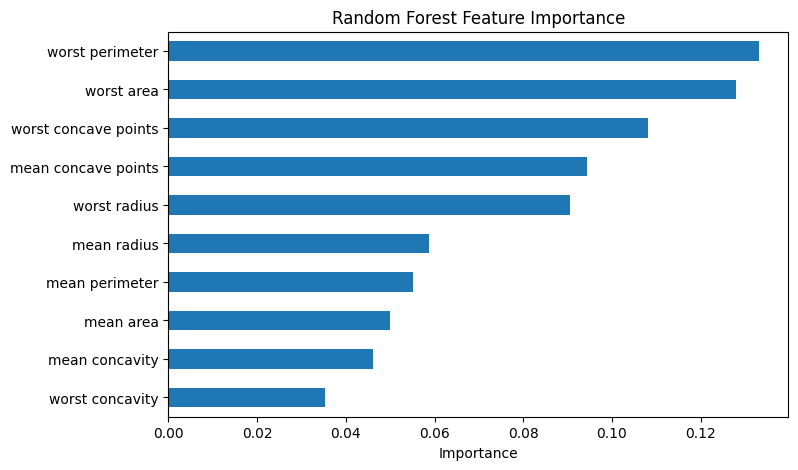

In [3]:
importance.head(10).sort_values().plot(
    kind="barh", figsize=(8, 5)
)
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.show()


### Tree feature importance limitation

It can be affected by feature cardinality and correlated features.

So do not blindly treat `feature_importances_` as the complete explanation.


# 3. PERMUTATION IMPORTANCE

Idea:

1. Measure normal model performance.
2. Shuffle one feature.
3. Measure performance again.
4. Large performance drop → feature was important.

Mental model:

```text
Original score = 95%
Shuffle feature A
New score = 70%
Large drop → A is important
```


In [4]:
result = permutation_importance(
    model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="accuracy"
)

perm_importance = pd.Series(
    result.importances_mean,
    index=data.feature_names
).sort_values(ascending=False)

print(perm_importance.head(10))


compactness error          0.008772
mean area                  0.008772
worst perimeter            0.008772
worst area                 0.007895
mean concave points        0.007895
worst texture              0.007018
mean radius                0.007018
worst radius               0.007018
concave points error       0.006140
worst fractal dimension    0.005263
dtype: float64


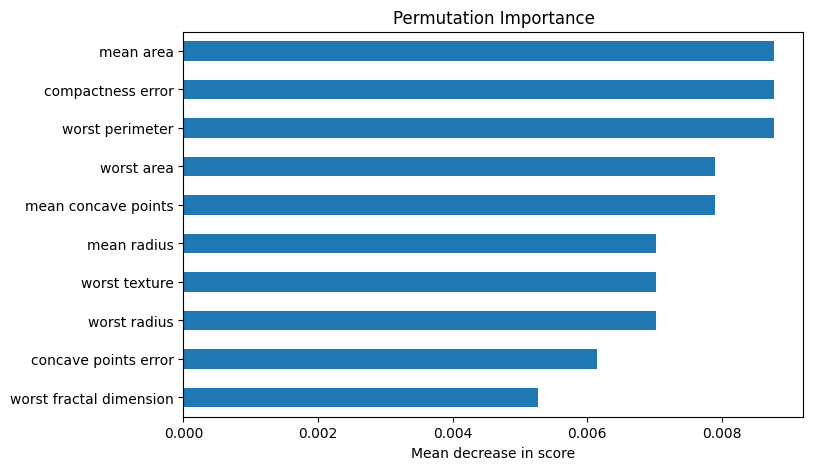

In [5]:
perm_importance.head(10).sort_values().plot(
    kind="barh", figsize=(8, 5)
)
plt.title("Permutation Importance")
plt.xlabel("Mean decrease in score")
plt.show()


### Important parameters

`n_repeats` → how many times each feature is shuffled.

`scoring` → metric used to measure performance drop.

`random_state` → reproducible shuffling.


# 4. TREE IMPORTANCE vs PERMUTATION IMPORTANCE

Tree importance:
> What happened inside the tree splits?

Permutation importance:
> What happens to model performance if I destroy this feature?

Permutation importance is often easier to explain intuitively.


# 5. LINEAR MODEL COEFFICIENTS

Linear model:

`y = w1*x1 + w2*x2 + ... + b`

Positive coefficient → increases model output.
Negative coefficient → decreases model output.

Compare coefficient magnitudes carefully when features have different scales.


In [6]:
# Logistic regression coefficients

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000))
])

pipeline.fit(X_train, y_train)

coefficients = pd.Series(
    pipeline.named_steps["model"].coef_[0],
    index=data.feature_names
).sort_values(key=np.abs, ascending=False)

print(coefficients.head(10))


worst texture          -1.255088
radius error           -1.082965
worst concave points   -0.953686
worst area             -0.947756
worst radius           -0.947616
worst symmetry         -0.939181
area error             -0.929104
worst concavity        -0.823151
worst perimeter        -0.763220
worst smoothness       -0.746625
dtype: float64


# 6. SHAP — CORE IDEA

SHAP = SHapley Additive exPlanations.

Mental model:

```text
Baseline prediction
        +
Feature A contribution
        +
Feature B contribution
        +
Feature C contribution
        =
Final prediction
```

SHAP explains how much each feature contributed to moving a prediction away from a baseline.

Positive contribution → pushes explained output upward.
Negative contribution → pushes explained output downward.

Exact interpretation depends on the model output being explained.


In [7]:
# Install once if required:
# pip install shap

try:
    import shap
    print("SHAP version:", shap.__version__)
except ImportError:
    print("SHAP is not installed. Run: pip install shap")


SHAP version: 0.49.1


In [8]:
# SHAP TreeExplainer

import shap

explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test)

# Binary classifiers return one explanation per class.
# Plot the positive-class (class 1) explanation.
if shap_values.values.ndim == 3:
    shap_values = shap_values[..., 1]
shap_values.feature_names = list(data.feature_names)   # X_test is a plain array, so add the names for the plots

print("SHAP values calculated.")


SHAP values calculated.


# 7. SHAP GLOBAL IMPORTANCE

Mean absolute SHAP value is commonly used:

`importance = mean(abs(SHAP value))`

Absolute value prevents positive and negative contributions from cancelling.


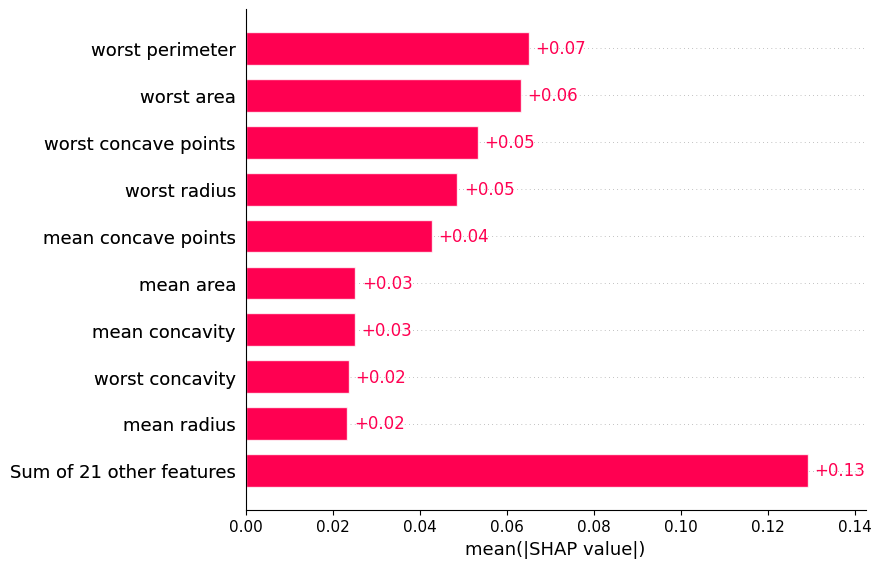

In [9]:
shap.plots.bar(
    shap_values,
    max_display=10
)


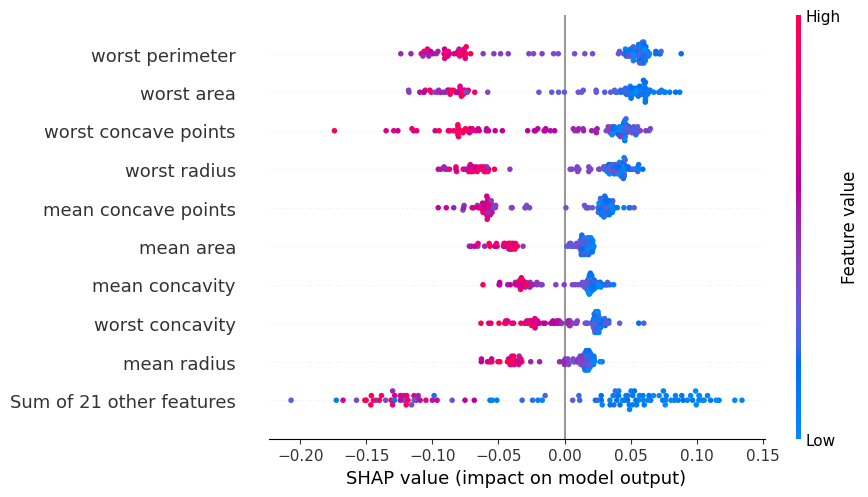

In [10]:
# SHAP summary / beeswarm

shap.plots.beeswarm(
    shap_values,
    max_display=10
)


# 8. SHAP LOCAL EXPLANATION

Global:
> What does the model generally use?

Local:
> Why did the model make this particular prediction?


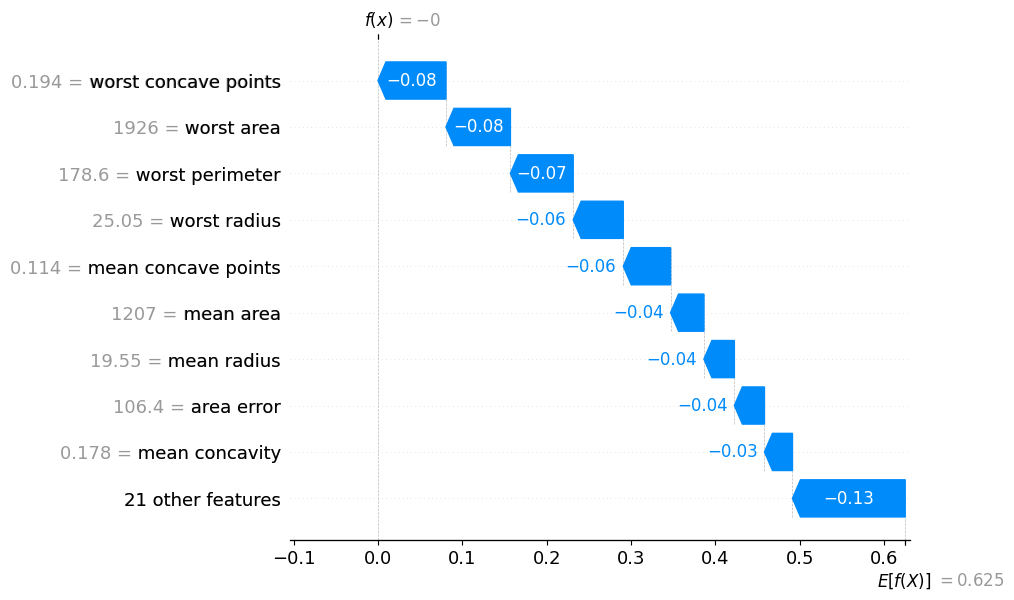

In [11]:
sample_index = 0

shap.plots.waterfall(
    shap_values[sample_index],
    max_display=10
)


# 9. PDP — PARTIAL DEPENDENCE PLOT

PDP asks:

> What happens to the average model prediction as one feature changes?

It is mainly a global explanation.

```text
Change feature
      ↓
Generate predictions
      ↓
Average predictions
      ↓
Plot relationship
```


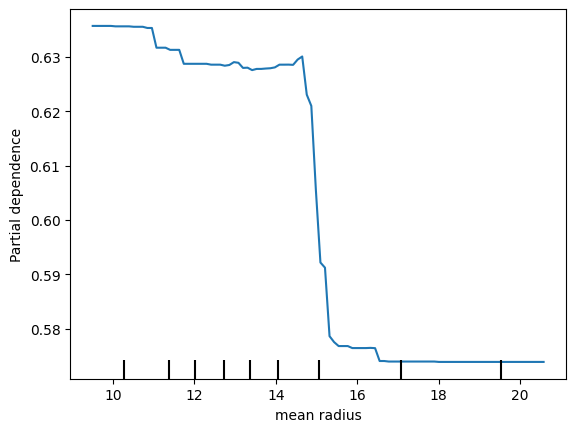

In [12]:
PartialDependenceDisplay.from_estimator(
    model,
    X,
    features=[0],
    feature_names=data.feature_names
)
plt.show()


# 10. ICE — INDIVIDUAL CONDITIONAL EXPECTATION

PDP averages across samples.

ICE shows the effect separately for individual samples.

PDP:
many samples → average curve

ICE:
many samples → many individual curves


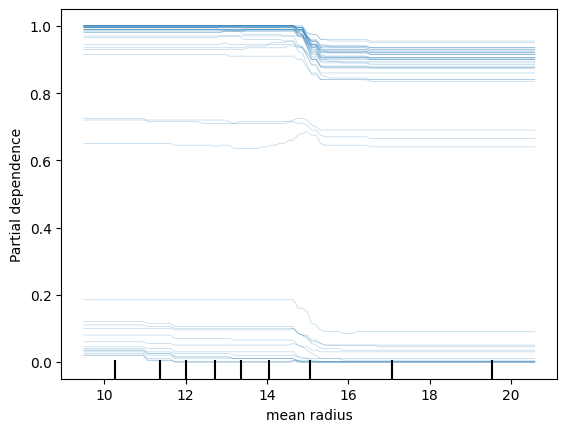

In [13]:
PartialDependenceDisplay.from_estimator(
    model,
    X,
    features=[0],
    kind="individual",
    subsample=50,
    random_state=42,
    feature_names=data.feature_names
)
plt.show()


# 11. PDP vs ICE

| Method | Main question |
|---|---|
| PDP | What is the average effect of a feature? |
| ICE | How does the effect differ between samples? |
| SHAP | How much did each feature contribute? |
| Permutation | How much does performance change if feature is shuffled? |
| Tree importance | How much did feature reduce impurity? |
| Coefficients | What direction/magnitude does a linear feature have? |


# 12. CORRELATED FEATURES

Suppose Age and Years of Experience contain similar information.

If Age is shuffled, Experience may still preserve the information.

Therefore Age can appear unimportant even though it is predictive.

**Important interview point:** correlated features can make feature importance unstable or misleading.


# 13. EXPLAINABILITY ≠ CAUSALITY

If a feature is important to a model, that does NOT prove the feature causes the target.

Explainability:
> How does the model behave?

Causal inference:
> What happens if we intervene on a variable?

They are different questions.


# 14. REGRESSION EXPLAINABILITY

The same methods work for regression.


In [14]:
housing = fetch_california_housing()

X_reg = pd.DataFrame(
    housing.data,
    columns=housing.feature_names
)

y_reg = housing.target

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

regressor = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

regressor.fit(X_train_r, y_train_r)

pred = regressor.predict(X_test_r)

print(
    "RMSE:",
    np.sqrt(mean_squared_error(y_test_r, pred))
)

print(
    pd.Series(
        regressor.feature_importances_,
        index=X_reg.columns
    ).sort_values(ascending=False)
)


RMSE: 0.5039082229141043
MedInc        0.525916
AveOccup      0.138125
Latitude      0.088588
Longitude     0.088338
HouseAge      0.054342
AveRooms      0.044394
Population    0.030637
AveBedrms     0.029659
dtype: float64


In [15]:
# Regression permutation importance

result = permutation_importance(
    regressor,
    X_test_r,
    y_test_r,
    n_repeats=10,
    random_state=42,
    scoring="neg_mean_squared_error"
)

importance = pd.Series(
    result.importances_mean,
    index=X_reg.columns
).sort_values(ascending=False)

print(importance)


MedInc        0.968012
Latitude      0.581590
Longitude     0.441310
AveOccup      0.266755
HouseAge      0.094996
AveRooms      0.034726
AveBedrms     0.012667
Population    0.010967
dtype: float64


# 15. LIME: A LOCAL SURROGATE MODEL

LIME (Local Interpretable Model-agnostic Explanations) explains one prediction of any model:

```text
1. make thousands of perturbed copies of the row
2. ask the model to predict each copy
3. weight each copy by how close it is to the original row
4. fit a simple weighted linear model on the copies; its coefficients are the explanation
```

A coefficient says how the prediction changes **locally** when that feature goes up. The `lime` package does this for tabular data, text and images;
below is the same idea from scratch, compared with SHAP on the same row.

In [16]:
import warnings
warnings.filterwarnings("ignore", message=".*encountered in matmul", category=RuntimeWarning)

import numpy as np
import pandas as pd
import shap
from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import Ridge
from sklearn.model_selection import train_test_split

data = load_breast_cancer()
names = np.array(data.feature_names)
X_tr, X_te, y_tr, y_te = train_test_split(data.data, data.target, test_size=0.25, stratify=data.target, random_state=42)
forest = RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1).fit(X_tr, y_tr)
mean, std = X_tr.mean(axis=0), X_tr.std(axis=0)


def lime_explain(row, n_samples=5000, seed=0, top=5):
    """Weighted linear model fitted to the forest's predictions on perturbed copies of `row`."""
    rng = np.random.default_rng(seed)
    centre = (row - mean) / std                                       # work in standard units
    samples = centre + rng.normal(size=(n_samples, len(row)))
    p_benign = forest.predict_proba(samples * std + mean)[:, 1]
    width = 0.75 * np.sqrt(len(row))                                  # kernel width, the lime package's default rule
    weights = np.exp(-((samples - centre) ** 2).sum(axis=1) / width ** 2)
    local = Ridge(alpha=1.0).fit(samples, p_benign, sample_weight=weights)
    return pd.Series(local.coef_, index=names).sort_values(key=abs, ascending=False).head(top)


row = X_te[0]
print(f"forest's P(benign) for this row: {forest.predict_proba(row.reshape(1, -1))[0, 1]:.3f}\n")
lime_0, lime_1 = lime_explain(row, seed=0), lime_explain(row, seed=1)
print("LIME, seed 0:", lime_0.round(3).to_dict())
print("LIME, seed 1:", lime_1.round(3).to_dict())

values = np.array(shap.TreeExplainer(forest).shap_values(row.reshape(1, -1)))
benign = values[0, :, 1] if values.ndim == 3 else values[1][0]
shap_top = pd.Series(benign, index=names).sort_values(key=abs, ascending=False).head(5)
print("SHAP:        ", shap_top.round(3).to_dict())
print(f"\nshared top-5 features: LIME seed 0 vs seed 1: {len(set(lime_0.index) & set(lime_1.index))}, LIME vs SHAP: {len(set(lime_0.index) & set(shap_top.index))}")


forest's P(benign) for this row: 0.997

LIME, seed 0: {'worst area': -0.061, 'worst perimeter': -0.047, 'worst radius': -0.044, 'worst concave points': -0.037, 'worst texture': -0.026}
LIME, seed 1: {'worst area': -0.061, 'worst radius': -0.043, 'worst perimeter': -0.043, 'worst concave points': -0.036, 'area error': -0.025}
SHAP:         {'worst concave points': 0.059, 'worst area': 0.054, 'worst radius': 0.051, 'worst perimeter': 0.047, 'mean concave points': 0.039}

shared top-5 features: LIME seed 0 vs seed 1: 4, LIME vs SHAP: 4


The forest is sure this tumour is benign (0.997). LIME and SHAP agree on 4 of their top 5 features (worst area, perimeter, radius, concave points).
Their signs differ because they answer different questions: LIME's coefficient is a local slope (if worst area went up, P(benign) would fall),
while SHAP's value is what this row's actual value contributes compared with the average prediction (its small area pushes towards benign).
Changing LIME's random seed swapped one of its top 5 features ("worst texture" for "area error").

| | LIME | SHAP |
|---|---|---|
| Idea | a simple model fitted around one prediction | Shapley values: each feature's fair share of the prediction |
| Works with | any model; it only needs `predict` | any model (KernelSHAP); fast exact versions for trees (TreeSHAP) |
| Gain | simple; model-agnostic; works on text and images | consistent; the values add up to the prediction; local and global views |
| Cost | results depend on the kernel width and random samples, so they can change between runs | KernelSHAP is slow; both assume features can be varied independently |
| Pick it when | a quick local explanation of a black box, text or images | tabular models, especially trees; reports and audits |

# 16. EXPLAINABILITY WORKFLOW

```text
Train model
    ↓
Evaluate model
    ↓
Global explanation
    ├── Feature importance
    ├── Permutation importance
    └── SHAP summary
    ↓
Feature relationship
    ├── PDP
    └── ICE
    ↓
Individual prediction
    └── SHAP local explanation
    ↓
Investigate unexpected behavior
```


# 17. COMMON MISTAKES

1. Treating feature importance as causality.
2. Assuming one explanation method is always correct.
3. Ignoring correlated features.
4. Comparing raw linear coefficients without considering scaling.
5. Using only global explanation when the question is local.
6. Assuming an explanation plot automatically makes a model trustworthy.
7. Ignoring what model output is actually being explained.
8. Explaining a bad model instead of first validating the model itself.


# 18. INTERVIEW CHEAT SHEET

### What is explainability?
Understanding how model inputs influence predictions.

### Global vs local?
Global explains overall model behavior. Local explains one prediction.

### What is permutation importance?
Shuffle a feature and measure the resulting performance decrease.

### Tree importance vs permutation importance?
Tree importance comes from internal split/impurity reduction. Permutation importance measures the effect of disrupting a feature on actual model performance.

### What is SHAP?
A Shapley-value-based method that assigns feature contributions to a prediction relative to a baseline.

### What does positive SHAP mean?
The feature pushes the explained model output upward relative to the baseline.

### What is PDP?
Average model response as a feature changes.

### PDP vs ICE?
PDP averages across samples; ICE shows individual sample response curves.

### Does importance imply causality?
No.

### Why are correlated features difficult?
One correlated feature can compensate for another, changing the measured importance.

### What should I use?
Tree model → tree importance + permutation + SHAP.
Linear model → coefficients + SHAP when needed.
Feature-response relationship → PDP/ICE.
Single prediction → local SHAP.


# 19. FINAL MENTAL MODEL

```text
                 MODEL
                   |
          ┌────────┴────────┐
          ↓                 ↓
       GLOBAL             LOCAL
          |                 |
    ┌─────┼─────┐           |
    ↓     ↓     ↓           ↓
 Tree   Perm.  SHAP        SHAP
 Imp.   Imp.
          |
          ↓
     Relationships
       ┌──┴──┐
       ↓     ↓
      PDP   ICE
```

Remember:

- Feature importance → Which features matter?
- Permutation → What happens if I destroy a feature?
- SHAP → How much did each feature contribute?
- PDP → What is the average feature-response relationship?
- ICE → How does that relationship differ by sample?

For our interview preparation, understand the intuition, limitations, use cases, and sklearn/API usage.

**Do not implement SHAP/PDP from scratch.**
